# 03 · Random Forest baseline
Handcrafted timing (RR) + shape features → class-weighted Random Forest. Tuned on validation (macro-F1). Test set not used here.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/ECG_Arrhythmia_Classification/src')

import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

from config import *

def load(name):
    d = np.load(f'{PROC_DIR}/{name}.npz')
    return {k: d[k] for k in d.files}

train, val = load('train'), load('val')      # test stays closed 🔒
print("Train:", train['X_mv'].shape, "| Val:", val['X_mv'].shape)
print("RR features:", train['rr'].shape[1], "->", RR_COLS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: (39015, 252) | Val: (11954, 252)
RR features: 8 -> ['pre_rr', 'post_rr', 'local_rr', 'long_rr', 'rel_pre_local', 'rel_post_local', 'rel_pre_long', 'rel_post_long']


In [2]:
SHAPE_COLS = ['r_amp', 'q_amp', 's_amp', 'qrs_width_ms', 'qrs_area',
              't_max', 't_min', 'beat_std', 'peak_to_peak']
R = BEFORE   # R-peak sits at index 90 in every window

def qrs_width_ms(a, max_half=40):
    """Width of the spike at half its height (a = absolute beat)."""
    half = 0.5 * a[R]
    l = R
    while l > R - max_half and a[l] > half:
        l -= 1
    r = R
    while r < R + max_half and a[r] > half:
        r += 1
    return (r - l) / FS * 1000

def shape_features(X_mv):
    x = X_mv - np.median(X_mv[:, :60], axis=1, keepdims=True)   # level before the beat = 0
    a = np.abs(x)
    return np.column_stack([
        x[:, R],                                    # r_amp
        x[:, R - 30:R].min(axis=1),                 # q_amp
        x[:, R:R + 30].min(axis=1),                 # s_amp
        np.array([qrs_width_ms(row) for row in a]), # qrs_width_ms
        a[:, R - 20:R + 30].sum(axis=1) / FS,       # qrs_area
        x[:, R + 50:].max(axis=1),                  # t_max
        x[:, R + 50:].min(axis=1),                  # t_min
        x.std(axis=1),                              # beat_std
        x.max(axis=1) - x.min(axis=1),              # peak_to_peak
    ]).astype(np.float32)

FEATURES = RR_COLS + SHAPE_COLS
Xtr = np.hstack([train['rr'], shape_features(train['X_mv'])])
Xva = np.hstack([val['rr'],   shape_features(val['X_mv'])])
ytr, yva = train['y'], val['y']

print("Feature matrix:", Xtr.shape, Xva.shape)

df = pd.DataFrame(Xtr, columns=FEATURES)
df['cls'] = train['cls']
print("\nMedian features per class (train):")
print(df.groupby('cls')[['rel_pre_long', 'rel_post_long', 'qrs_width_ms', 'r_amp', 'qrs_area']].median().round(3))

Feature matrix: (39015, 17) (11954, 17)

Median features per class (train):
     rel_pre_long  rel_post_long  qrs_width_ms  r_amp  qrs_area
cls                                                            
F           1.014          0.816        41.667  1.950     0.100
N           1.006          0.996        30.556  1.623     0.059
S           0.624          0.667        25.000  1.165     0.042
V           0.720          1.262        72.222  1.334     0.121


In [3]:
dummy = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
p = dummy.predict(Xva)
print("Accuracy :", round((p == yva).mean(), 3))
print("Macro-F1 :", round(f1_score(yva, p, average='macro'), 3))
print("Abnormal recall:", recall_score(yva, p))

Accuracy : 0.955
Macro-F1 : 0.488
Abnormal recall: 0.0


In [4]:
def evaluate(y_true, y_pred, cls):
    return {
        'macro_f1':     round(f1_score(y_true, y_pred, average='macro'), 4),
        'ab_precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'ab_recall':    round(recall_score(y_true, y_pred), 4),
        **{f'recall_{c}': round((y_pred[cls == c] == 1).mean(), 4) for c in 'SVF'},
    }

results, best, best_f1 = [], None, -1
for depth in [None, 20, 10]:
    for leaf in [1, 5, 20]:
        t0 = time.time()
        rf = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                    class_weight='balanced', n_jobs=-1, random_state=SEED)
        rf.fit(Xtr, ytr)
        m = evaluate(yva, rf.predict(Xva), val['cls'])
        m.update({'max_depth': depth, 'min_samples_leaf': leaf, 'sec': round(time.time() - t0, 1)})
        results.append(m)
        print(m)
        if m['macro_f1'] > best_f1:
            best, best_f1 = rf, m['macro_f1']

grid = pd.DataFrame(results).sort_values('macro_f1', ascending=False)
grid.to_csv(f'{RES_DIR}/rf_grid_val.csv', index=False)
print("\nBest settings:\n", grid.iloc[0])

{'macro_f1': 0.8818, 'ab_precision': 1.0, 'ab_recall': 0.6292, 'recall_S': np.float64(0.7489), 'recall_V': np.float64(0.5738), 'recall_F': np.float64(0.0), 'max_depth': None, 'min_samples_leaf': 1, 'sec': 75.2}
{'macro_f1': 0.9335, 'ab_precision': 0.9976, 'ab_recall': 0.7749, 'recall_S': np.float64(0.793), 'recall_V': np.float64(0.8054), 'recall_F': np.float64(0.0), 'max_depth': None, 'min_samples_leaf': 5, 'sec': 76.4}
{'macro_f1': 0.9174, 'ab_precision': 0.8225, 'ab_recall': 0.8635, 'recall_S': np.float64(0.8326), 'recall_V': np.float64(0.9362), 'recall_F': np.float64(0.0), 'max_depth': None, 'min_samples_leaf': 20, 'sec': 60.5}
{'macro_f1': 0.8738, 'ab_precision': 1.0, 'ab_recall': 0.6089, 'recall_S': np.float64(0.7269), 'recall_V': np.float64(0.5537), 'recall_F': np.float64(0.0), 'max_depth': 20, 'min_samples_leaf': 1, 'sec': 65.9}
{'macro_f1': 0.9328, 'ab_precision': 0.9976, 'ab_recall': 0.7731, 'recall_S': np.float64(0.793), 'recall_V': np.float64(0.802), 'recall_F': np.float64(0

              precision    recall  f1-score   support

      Normal      0.990     1.000     0.995     11412
    Abnormal      0.993     0.788     0.879       542

    accuracy                          0.990     11954
   macro avg      0.992     0.894     0.937     11954
weighted avg      0.990     0.990     0.990     11954

Per-subtype recall: {'recall_S': np.float64(0.7885), 'recall_V': np.float64(0.8322), 'recall_F': np.float64(0.0)}


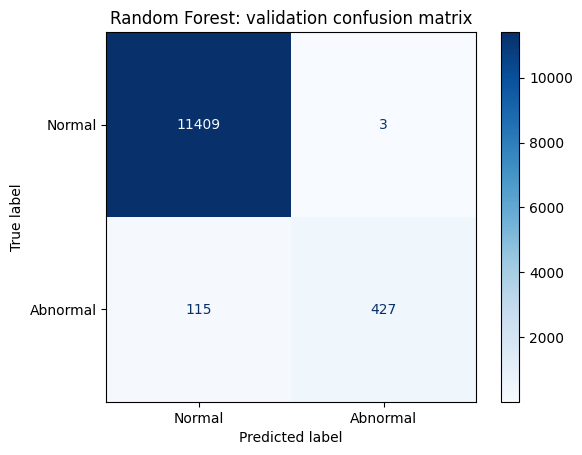

✅ Model and metrics saved


In [5]:
p_va = best.predict(Xva)
print(classification_report(yva, p_va, target_names=['Normal', 'Abnormal'], digits=3))

val_metrics = evaluate(yva, p_va, val['cls'])
print("Per-subtype recall:", {k: v for k, v in val_metrics.items() if k.startswith('recall_')})

ConfusionMatrixDisplay(confusion_matrix(yva, p_va),
                       display_labels=['Normal', 'Abnormal']).plot(cmap='Blues', values_format='d')
plt.title('Random Forest: validation confusion matrix')
plt.savefig(f'{FIG_DIR}/07_rf_val_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

joblib.dump(best, f'{MODEL_DIR}/rf_best.joblib', compress=3)
with open(f'{RES_DIR}/rf_val_metrics.json', 'w') as f:
    json.dump({'params': best.get_params(), 'val': val_metrics}, f, indent=2, default=str)
print("✅ Model and metrics saved")

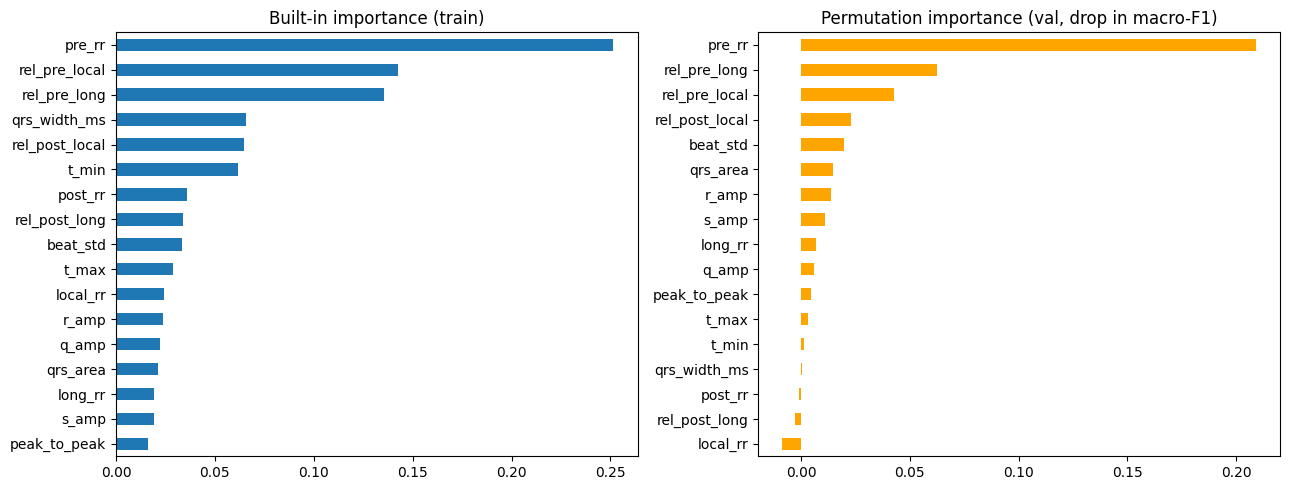

In [6]:
imp = pd.Series(best.feature_importances_, index=FEATURES).sort_values()

perm = permutation_importance(best, Xva, yva, scoring='f1_macro',
                              n_repeats=5, random_state=SEED, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
imp.plot(kind='barh', ax=axes[0], title='Built-in importance (train)')
perm_imp.plot(kind='barh', ax=axes[1], color='orange',
              title='Permutation importance (val, drop in macro-F1)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/08_rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
params = dict(n_estimators=300, max_depth=best.max_depth, min_samples_leaf=best.min_samples_leaf,
              class_weight='balanced', n_jobs=-1, random_state=SEED)
groups = {'RR only (timing)': list(range(8)),
          'Shape only':       list(range(8, 17)),
          'RR + shape':       list(range(17))}

rows = []
for name, cols in groups.items():
    rf = RandomForestClassifier(**params).fit(Xtr[:, cols], ytr)
    rows.append({'features': name, **evaluate(yva, rf.predict(Xva[:, cols]), val['cls'])})

ablation = pd.DataFrame(rows).set_index('features')
ablation.to_csv(f'{RES_DIR}/rf_ablation_val.csv')
print(ablation)

                  macro_f1  ab_precision  ab_recall  recall_S  recall_V  \
features                                                                  
RR only (timing)    0.9001        0.8966     0.7362    0.8282    0.7081   
Shape only          0.5336        0.1092     0.4520    0.1233    0.7181   
RR + shape          0.9367        0.9930     0.7878    0.7885    0.8322   

                  recall_F  
features                    
RR only (timing)    0.0000  
Shape only          0.1765  
RR + shape          0.0000  


## Key findings (validation only, test not used)
- Best RF: max_depth=10, min_samples_leaf=5, 300 trees, balanced class weights → **macro-F1 0.937**, abnormal precision 0.993, recall 0.788.
- Lazy "always Normal" model: accuracy 0.955 but macro-F1 0.488 → accuracy is misleading here.
- Ablation: shape only 0.534 · RR only 0.900 · RR + shape 0.937.
- S beats need timing (S recall: shape 0.12 vs RR 0.83). V beats benefit from both (0.83 combined).
- Handcrafted shape features transfer poorly to new patients (shape-only precision 0.11).
- min_samples_leaf=1 generalizes worst (memorizes training patients).
- F beats never detected (training F beats come almost only from patient 208).
- Top feature: pre_rr, then relative RR features.